MD# 04 | Accounting Fraud Signals (JAR2020)

RandomForest on the 14 financial ratios included in the Bao et al. (2020) dataset, with the paper's out-of-sample design: train on fiscal years 1991 to 2001, test on 2003 to 2008, one-year gap, and serial frauds spanning the split relabelled in training.

In [1]:
import sys, os
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from src.paths import RAW, PROCESSED, RESULTS
from src import setup_data

RESULTS.mkdir(exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
if not setup_data.data_present():
    setup_data.main()

/usr/local/lib/python3.12/dist-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.0.post2)/charset_normalizer (3.4.6) doesn't match a supported version!
  warnings.warn(


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.fraud_features import load_dataset, run_fraud_model, FRAUD_FEATURES, LABEL_COL

DATA = RAW / "jar_fraud" / "data_FraudDetection_JAR2020.csv"
df = load_dataset(DATA)
print(f"Shape: {df.shape}")
print(f"Fiscal years: {df.fyear.min()} to {df.fyear.max()}")
print(f"Fraud rate (misstate=1): {df[LABEL_COL].mean():.4%}")

Shape: (146045, 46)
Fiscal years: 1990 to 2014
Fraud rate (misstate=1): 0.6601%


In [3]:
res = run_fraud_model(DATA)

In [4]:
print(f"Test AUC (2003-2008 pooled): {res['auc']}")
print(f"  vs random baseline 0.50: {res['auc'] - 0.5:+.4f}")
print("  vs Bao et al. (2020): RUSBoost on 28 raw items about 0.725 (original paper);")
print("     2022 erratum reports logit on the 14 ratios between about 0.65 and 0.70 depending on test window")
print(f"\nAUC by test year: {res['yearly_auc']}")
print(f"Train / test rows: {res['train_size']:,} / {res['test_size']:,}")
print(f"Fraud rate train / test: {res['fraud_rate_train']:.2%} / {res['fraud_rate_test']:.2%}")
print(f"Frauds caught in top 1% of scores: {res['frauds_in_top1pct']} of {res['frauds_in_test']}")
print(f"Top 3 features: {res['top_features']}")

Test AUC (2003-2008 pooled): 0.6438
  vs random baseline 0.50: +0.1438
  vs Bao et al. (2020): RUSBoost on 28 raw items about 0.725 (original paper);
     2022 erratum reports logit on the 14 ratios between about 0.65 and 0.70 depending on test window

AUC by test year: {2003: 0.6704, 2004: 0.6656, 2005: 0.6116, 2006: 0.5764, 2007: 0.6341, 2008: 0.6812}
Train / test rows: 58,541 / 30,777
Fraud rate train / test: 0.63% / 0.81%
Frauds caught in top 1% of scores: 4 of 250
Top 3 features: ['soft_assets', 'reoa', 'ch_fcf']


MD Fraud is rare (well under 1% of firm-years), which is the main constraint here. The paper's best result uses RUSBoost on 28 raw accounting items rather than these 14 ratios; the ratio-based models in the paper sit in the same range as this RandomForest.

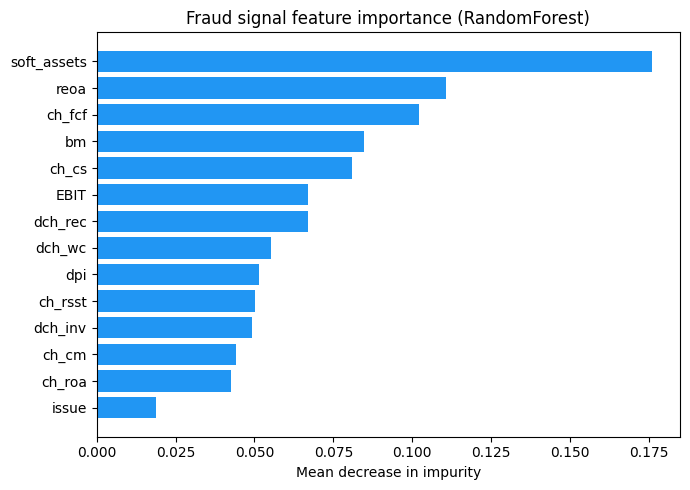

In [5]:
imp = res["feature_importance_df"].sort_values("importance")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp["feature"], imp["importance"], color="#2196F3")
ax.set_title("Fraud signal feature importance (RandomForest)")
ax.set_xlabel("Mean decrease in impurity")
plt.tight_layout()
plt.savefig(RESULTS / "fraud_feature_importance.png", dpi=150)
plt.show()

In [6]:
res["scores_df"].to_csv(RESULTS / "fraud_risk_scores.csv", index=False)
res["feature_importance_df"].to_csv(RESULTS / "fraud_feature_importance.csv", index=False)
summary = {k: res[k] for k in ["auc", "train_size", "test_size", "fraud_rate_train", "fraud_rate_test",
                               "frauds_in_test", "frauds_in_top1pct"]}
summary["test_years"] = "2003-2008"
summary["top_features"] = "|".join(res["top_features"])
pd.DataFrame([summary]).to_csv(RESULTS / "fraud_model_summary.csv", index=False)
print("Saved fraud_risk_scores.csv, fraud_feature_importance.csv, fraud_model_summary.csv")
res["scores_df"].head(10)

Saved fraud_risk_scores.csv, fraud_feature_importance.csv, fraud_model_summary.csv


,gvkey,fyear,p_aaer,misstate,fraud_score,risk_rank
0,3116,2003,NaN,0,0.806341,1
1,11934,2003,NaN,0,0.800566,2
2,24363,2007,NaN,0,0.797981,3
3,165680,2006,NaN,0,0.792460,4
4,177629,2007,NaN,0,0.783433,5
5,129441,2008,NaN,0,0.774375,6
6,63892,2005,NaN,0,0.772231,7
7,61377,2007,NaN,0,0.767921,8
8,164283,2007,NaN,0,0.763038,9
9,14490,2004,NaN,0,0.760805,10
